In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 05 — Neural networks (scikit-learn MLP)
No Dropout / BatchNorm in scikit-learn: regularisation by L2, few epochs and seed averaging. Report: `docs/phase6_neural_networks.md`.

In [2]:
table("phase6_nn_val.csv", index_col=0).drop(columns=["best_params", "f1_draw"]).round(4)

,log_loss,brier,rps,accuracy,f1_macro,ece,cv_log_loss
model,,,,,,,
MLP simple (1 hidden layer) [1 seed],0.9874,0.5880,0.2013,0.5283,0.3919,0.0203,0.9796
MLP simple (1 hidden layer) [5-seed avg],0.9868,0.5877,0.2011,0.5303,0.3941,0.0200,0.9796
MLP deep (2-3 hidden layers) [1 seed],0.9870,0.5876,0.2012,0.5286,0.3928,0.0198,0.9801
MLP deep (2-3 hidden layers) [5-seed avg],0.9864,0.5873,0.2010,0.5286,0.3934,0.0192,0.9801


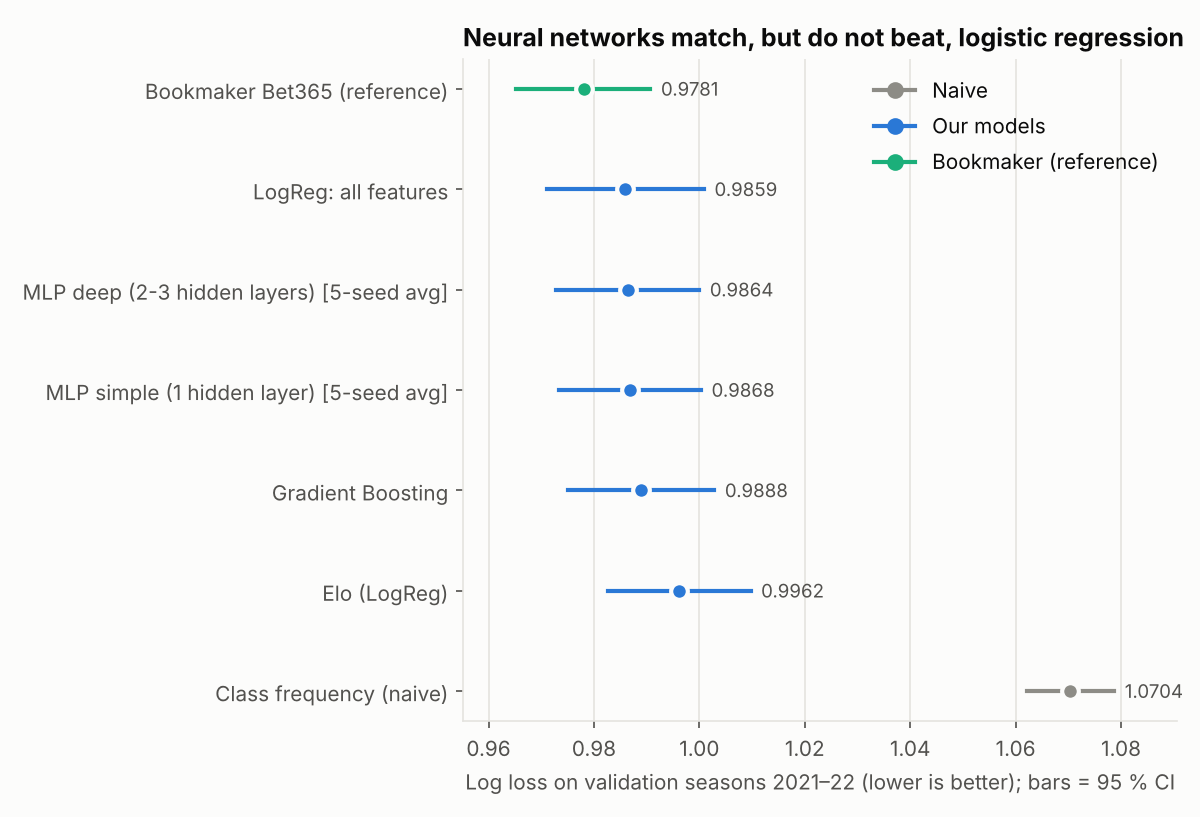

In [3]:
show("phase6_logloss.png", 800)

### Is the dataset big enough? Learning curve

In [4]:
table("phase6_learning_curve.csv").round(4)

,n_matches,seasons,LogReg,Gradient Boosting,MLP (3-seed avg)
0,1826,1,0.9976,0.9997,0.9940
1,3551,2,0.9926,0.9932,0.9904
2,5377,3,0.9894,0.9918,1.0169
3,9029,5,0.9889,0.9905,0.9882
4,12681,7,0.9869,0.9907,0.9887
5,18159,10,0.9859,0.9889,0.9872


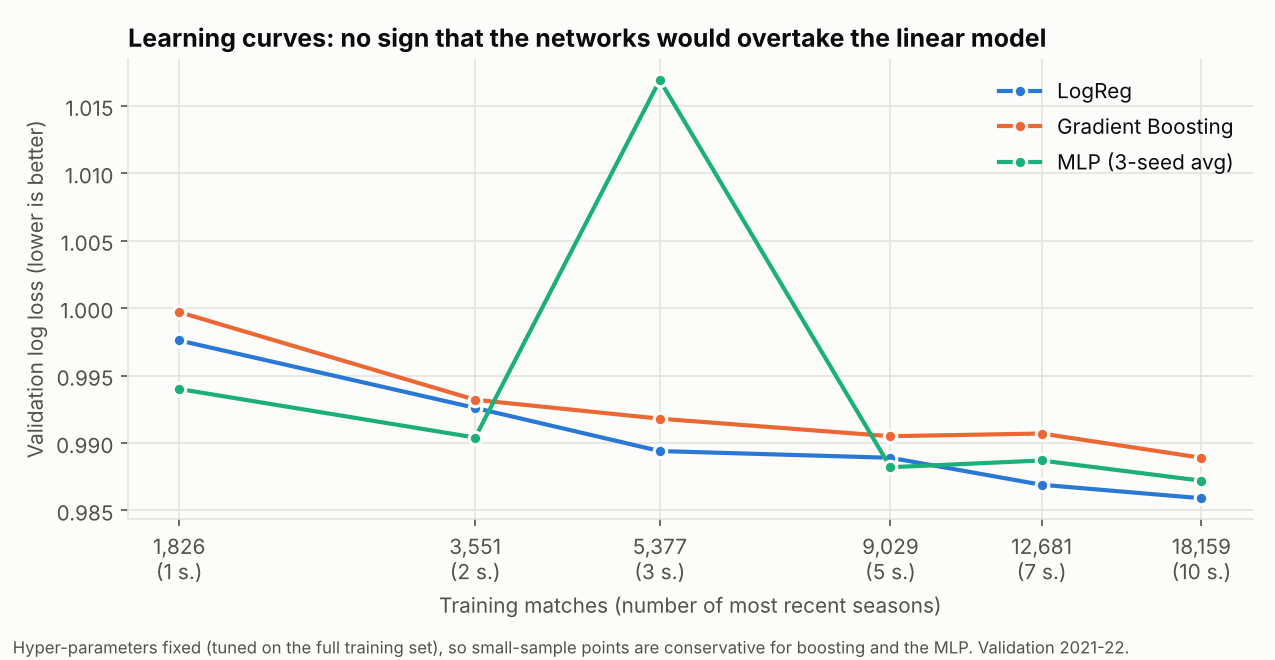

In [5]:
show("phase6_learning_curve.png")

**Decision.** None of the networks beats the logistic regression significantly: it stays the reference model. The best networks are strongly regularised toward near-linear functions.